In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity


Loading metadata...
    green_T_distractors      mean       std  count       sem
0                     0  1.000000  0.000000    101  0.000000
1                     1  0.812500  0.403113     16  0.100778
2                     2  0.815789  0.392859     38  0.063730
3                     3  0.784314  0.415390     51  0.058166
4                     4  0.828571  0.382385     35  0.064635
5                     5  0.645161  0.486373     31  0.087355
6                     6  0.760870  0.431266     46  0.063587
7                     7  0.659091  0.479495     44  0.072287
8                     8  0.651163  0.482243     43  0.073541
9                     9  0.567568  0.502247     37  0.082569
10                   10  0.641026  0.485971     39  0.077818
11                   11  0.468750  0.507007     32  0.089627
12                   12  0.617021  0.491369     47  0.071673
13                   13  0.743590  0.442359     39  0.070834
14                   14  0.533333  0.504525     45  0.075210
15  

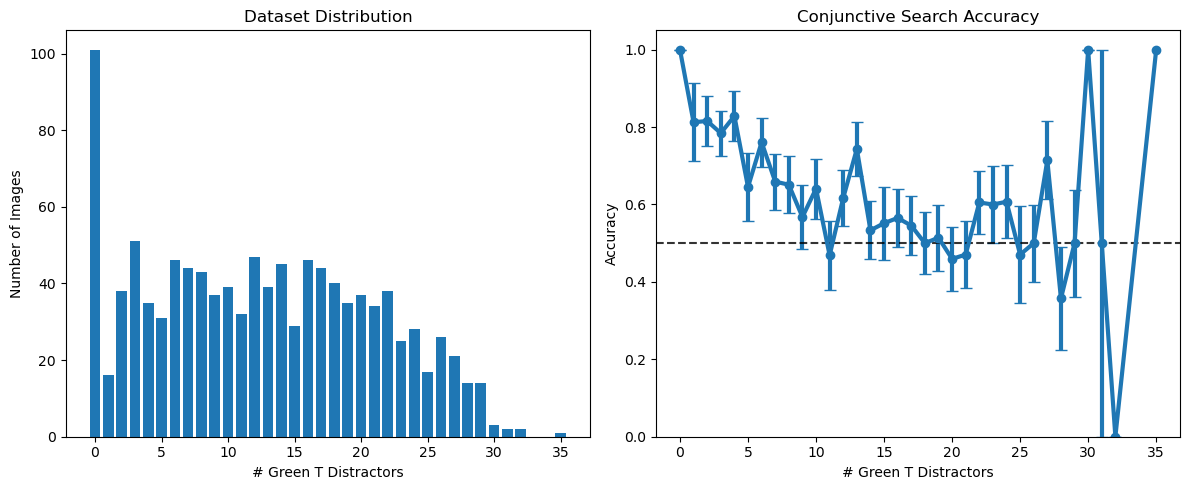

In [44]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Paths
# ==========================================================

RESULTS_PATH = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/"
    "Results/qwen_search_results_counterfactual_binary.csv"
)

DATASET_ROOT = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/"
    "search-dataset/visual_search_dataset_counterfactual"
)

# ==========================================================
# Load results
# ==========================================================

df = pd.read_csv(RESULTS_PATH)

# ==========================================================
# Load metadata
# ==========================================================

metadata_cache = {}

def count_green_T(row):

    condition = row["condition"]
    distractors = int(row["num_distractors"])
    trial = int(row["trial"])
    target_present = str(row["target_present"]).lower()

    json_path = os.path.join(
        DATASET_ROOT,
        condition,
        f"{condition}_distractors_{distractors}"
        f"_trial_{trial:03d}"
        f"_target_{target_present}.json",
    )

    if json_path not in metadata_cache:
        with open(json_path, "r") as f:
            metadata_cache[json_path] = json.load(f)

    return sum(
        obj["shape"] == "T"
        and obj["color"] == "green"
        for obj in metadata_cache[json_path]["objects"]
    )

print("Loading metadata...")
df["green_T_distractors"] = df.apply(
    count_green_T,
    axis=1,
)

# ==========================================================
# Only conjunctive search
# ==========================================================

df = df[df["condition"] == "conjunctive"].copy()

# ==========================================================
# Accuracy summary
# ==========================================================

summary = (
    df.groupby("green_T_distractors")["correct"]
      .agg(["mean", "std", "count"])
      .reset_index()
)

summary["sem"] = (
    summary["std"] /
    np.sqrt(summary["count"])
)

print(summary)

# ==========================================================
# Plot
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12,5)
)

# ----------------------------------------------------------
# Histogram
# ----------------------------------------------------------

axes[0].bar(
    summary["green_T_distractors"],
    summary["count"],
    width=0.8,
)

axes[0].set_xlabel("# Green T Distractors")
axes[0].set_ylabel("Number of Images")
axes[0].set_title("Dataset Distribution")

# ----------------------------------------------------------
# Accuracy
# ----------------------------------------------------------

axes[1].errorbar(
    summary["green_T_distractors"],
    summary["mean"],
    yerr=summary["sem"],
    marker="o",
    linewidth=3,
    capsize=4,
)

axes[1].axhline(
    0.5,
    color="black",
    linestyle="--",
    alpha=0.8,
)

axes[1].set_ylim(0,1.05)
axes[1].set_xlabel("# Green T Distractors")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Conjunctive Search Accuracy")

plt.tight_layout()
plt.show()

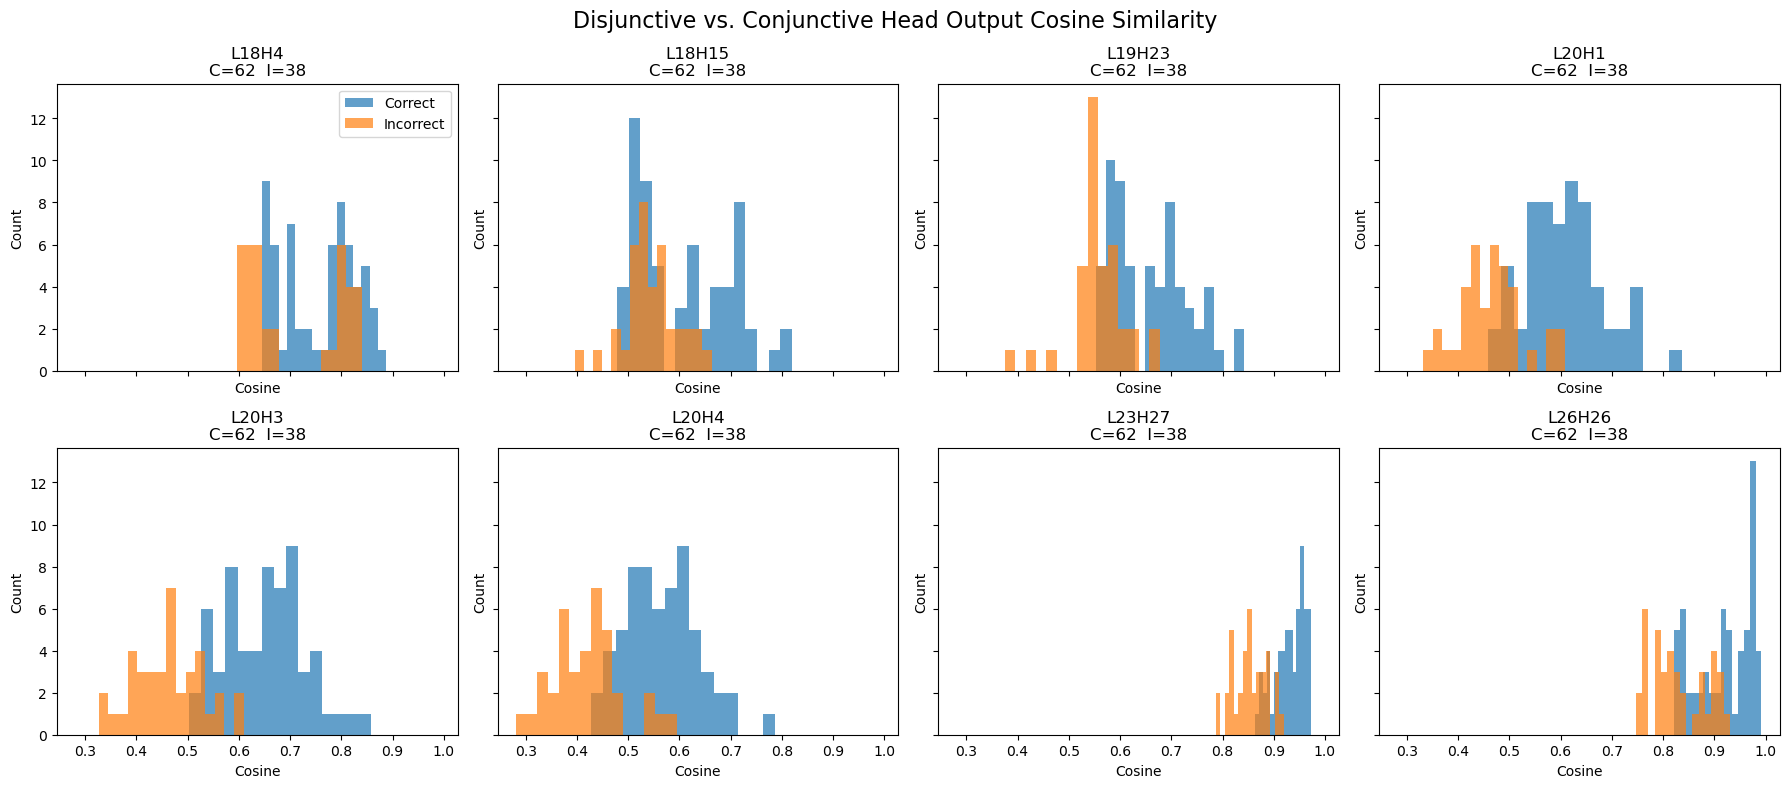

In [9]:


df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/top10_head_geometry_pairs.csv"
)

# Sort heads by layer/head
heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (_, h) in zip(axes, heads.iterrows()):

    layer = h["layer"]
    head = h["head"]

    subset = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ]

    correct = subset[subset["target_correct"]]
    incorrect = subset[~subset["target_correct"]]

    ax.hist(
        correct["cosine_similarity"],
        bins=15,
        alpha=0.7,
        label="Correct",
    )

    ax.hist(
        incorrect["cosine_similarity"],
        bins=15,
        alpha=0.7,
        label="Incorrect",
    )

    ax.set_title(
        f"L{layer}H{head}\n"
        f"C={len(correct)}  I={len(incorrect)}"
    )

    ax.set_xlabel("Cosine")
    ax.set_ylabel("Count")

axes[0].legend()

plt.suptitle(
    "Disjunctive vs. Conjunctive Head Output Cosine Similarity",
    fontsize=16,
)

plt.tight_layout()
plt.show()

Plotting heads:
   layer  head
0     20     1
1     20     3


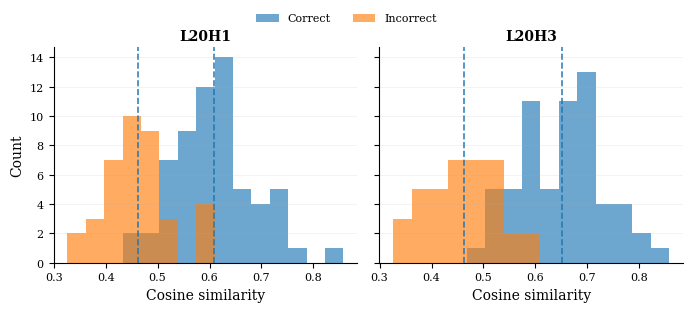

Saved PDF:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/figures/top2_head_cosine_similarity.pdf
Saved PNG:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/figures/top2_head_cosine_similarity.png


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ==========================================================
# PATHS
# ==========================================================

CSV_PATH = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results/"
    "top10_head_geometry_pairs.csv"
)

SAVE_DIR = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/figures"
)

os.makedirs(SAVE_DIR, exist_ok=True)

# ==========================================================
# NeurIPS-style plotting settings
# ==========================================================

rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ==========================================================
# LOAD
# ==========================================================

df = pd.read_csv(CSV_PATH)

# Preserve the order in which heads appear in the CSV
heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Keep only the top 2 ranked heads
top_heads = heads.head(2)

print("Plotting heads:")
print(top_heads)

# ==========================================================
# Determine common bins
# ==========================================================

# Using the same bins across both heads makes the
# distributions directly comparable.

plot_df = df.merge(
    top_heads,
    on=["layer", "head"],
    how="inner",
)

xmin = plot_df["cosine_similarity"].min()
xmax = plot_df["cosine_similarity"].max()

bins = np.linspace(xmin, xmax, 16)

# ==========================================================
# FIGURE
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(7.0, 3.0),
    sharex=True,
    sharey=True,
)

for i, (ax, (_, h)) in enumerate(zip(axes, top_heads.iterrows())):

    layer = int(h["layer"])
    head = int(h["head"])

    subset = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ]

    correct = subset[subset["target_correct"]]
    incorrect = subset[~subset["target_correct"]]

    # ------------------------------------------------------
    # Histograms
    # ------------------------------------------------------

    ax.hist(
        correct["cosine_similarity"],
        bins=bins,
        alpha=0.65,
        label="Correct",
        edgecolor="none",
    )

    ax.hist(
        incorrect["cosine_similarity"],
        bins=bins,
        alpha=0.65,
        label="Incorrect",
        edgecolor="none",
    )

    # ------------------------------------------------------
    # Mean lines
    # ------------------------------------------------------

    ax.axvline(
        correct["cosine_similarity"].mean(),
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    ax.axvline(
        incorrect["cosine_similarity"].mean(),
        linestyle="--",
        linewidth=1.2,
        alpha=0.9,
    )

    # ------------------------------------------------------
    # Formatting
    # ------------------------------------------------------

    ax.set_title(
        f"L{layer}H{head}",
        fontweight="bold",
        pad=5,
    )

    ax.set_xlabel("Cosine similarity")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        linewidth=0.5,
        alpha=0.2,
    )

    # Panel labels
    # ax.text(
    #     -0.13,
    #     1.05,
    #     chr(ord("A") + i),
    #     transform=ax.transAxes,
    #     fontsize=11,
    #     fontweight="bold",
    #     va="bottom",
    # )

axes[0].set_ylabel("Count")

# One shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
    frameon=False,
)

# ==========================================================
# SAVE
# ==========================================================

plt.tight_layout()

pdf_path = os.path.join(
    SAVE_DIR,
    "top2_head_cosine_similarity.pdf",
)

png_path = os.path.join(
    SAVE_DIR,
    "top2_head_cosine_similarity.png",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.03,
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03,
)

plt.show()

print(f"Saved PDF:\n{pdf_path}")
print(f"Saved PNG:\n{png_path}")

128 dimensions
1600 total vectors
L18H4: 200 vectors


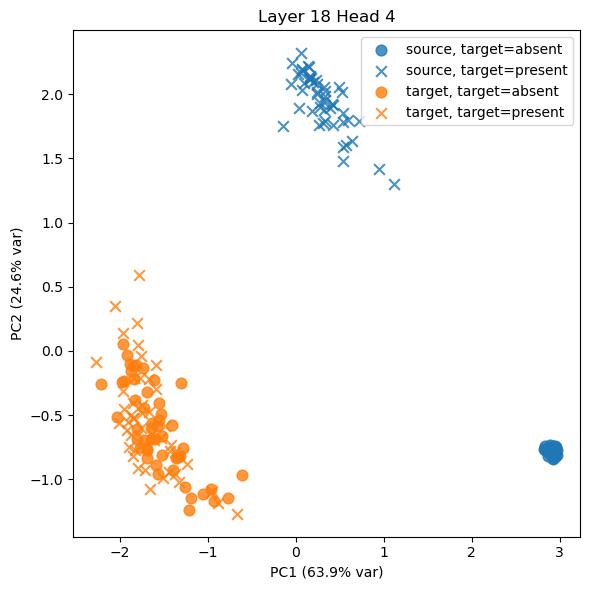

L18H15: 200 vectors


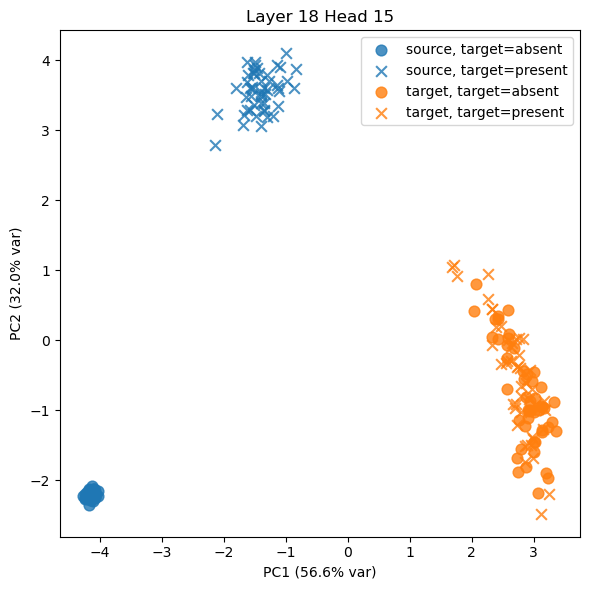

L19H23: 200 vectors


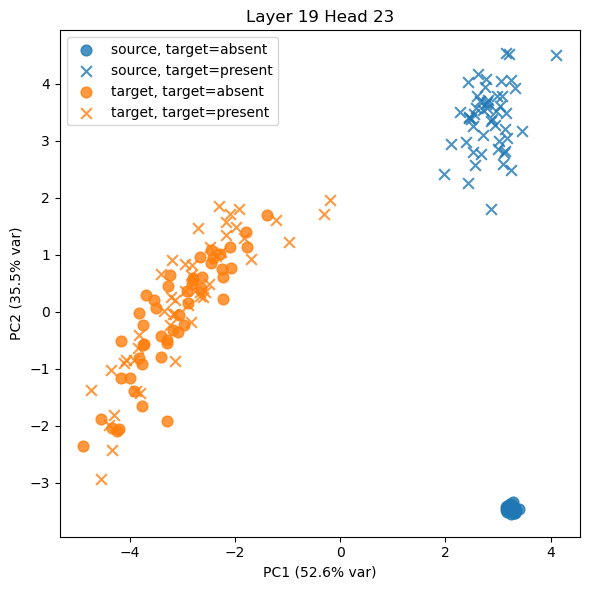

L20H1: 200 vectors


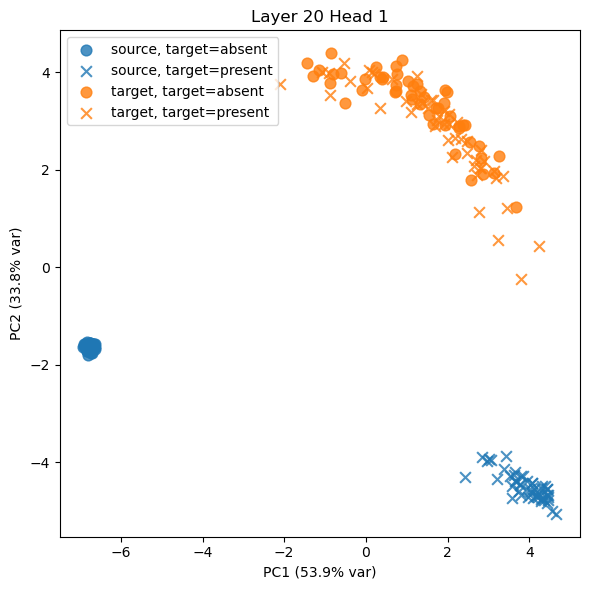

L20H3: 200 vectors


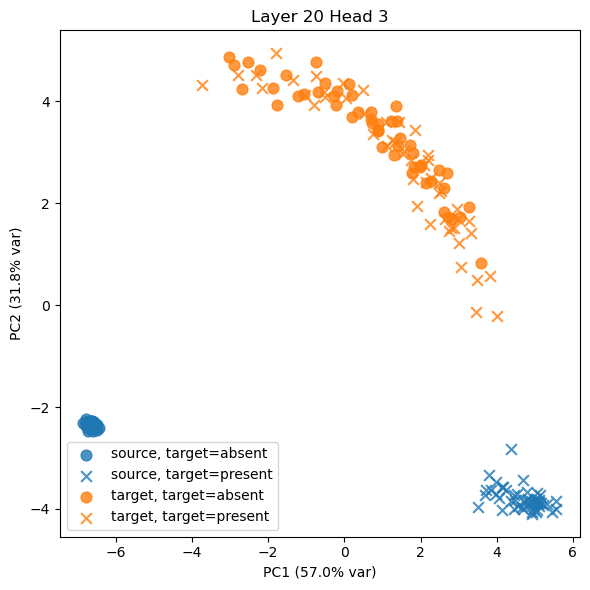

L20H4: 200 vectors


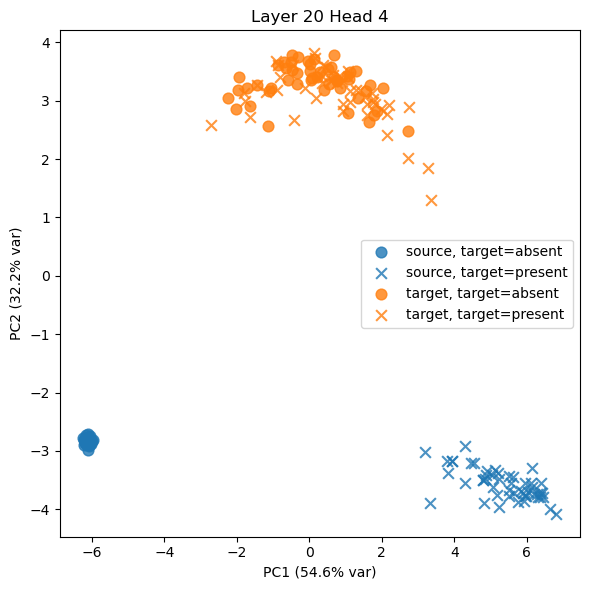

L23H27: 200 vectors


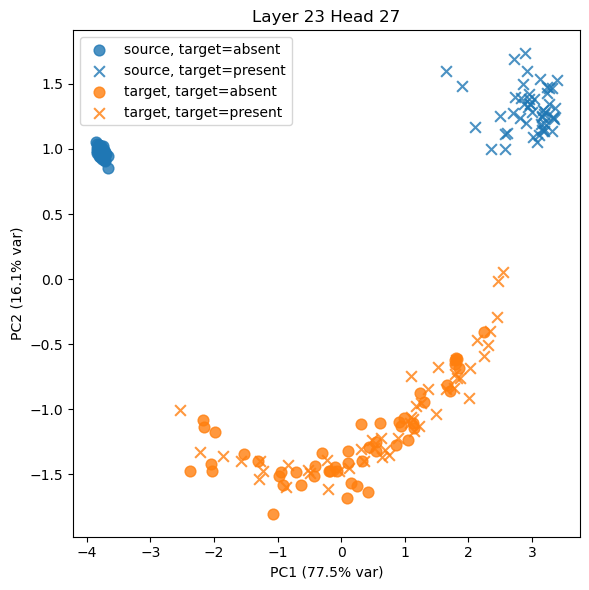

L26H26: 200 vectors


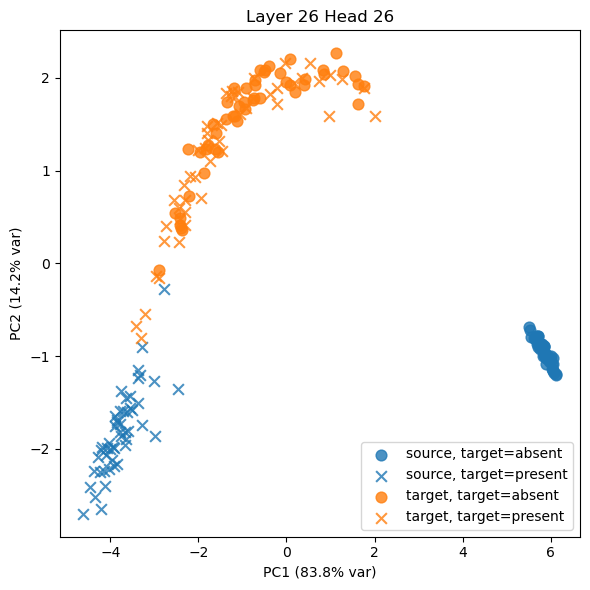

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================================
# Load data
# ==========================================================

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/top10_head_geometry.csv"
)

feature_cols = sorted(
    [c for c in df.columns if c.startswith("dim_")]
)

print(f"{len(feature_cols)} dimensions")
print(f"{len(df)} total vectors")

# ==========================================================
# PCA per head
# ==========================================================

heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
)

for layer, head in heads.itertuples(index=False):

    sub = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ].copy()

    print(f"L{layer}H{head}: {len(sub)} vectors")

    if len(sub) < 2:
        print("Skipping (not enough samples)")
        continue

    X = sub[feature_cols].to_numpy()

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X)

    sub["PC1"] = coords[:, 0]
    sub["PC2"] = coords[:, 1]

    plt.figure(figsize=(6, 6))

    colors = {
        "source": "tab:blue",
        "target": "tab:orange",
    }

    markers = {
        False: "o",   # target absent
        True: "x",    # target present
    }

    for role in ["source", "target"]:
        for present in [False, True]:

            pts = sub[
                (sub["condition_role"] == role) &
                (sub["target_present"] == present)
            ]

            plt.scatter(
                pts["PC1"],
                pts["PC2"],
                color=colors[role],
                marker=markers[present],
                s=60,
                alpha=0.8,
                label=f"{role}, target={'present' if present else 'absent'}",
            )

    plt.xlabel(
        f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% var)"
    )
    plt.ylabel(
        f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% var)"
    )

    plt.title(f"Layer {layer} Head {head}")
    plt.legend()
    plt.tight_layout()
    plt.show()

128 dimensions
1600 total vectors

Plotting top 2 heads:
   layer  head
0     20     1
1     20     3
L20H1: 200 vectors
L20H3: 200 vectors


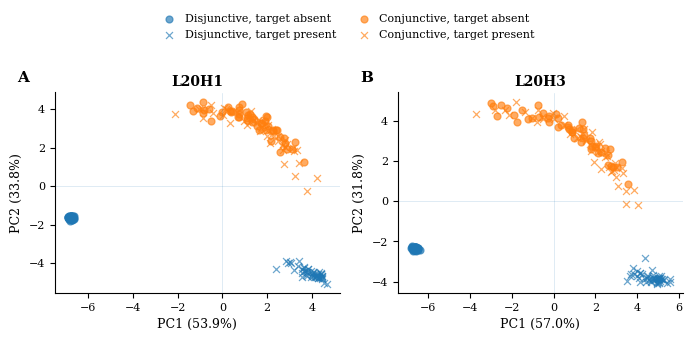

Saved PDF:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/figures/top2_head_geometry_pca.pdf
Saved PNG:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/figures/top2_head_geometry_pca.png


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.decomposition import PCA

# ==========================================================
# PATHS
# ==========================================================

CSV_PATH = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results/"
    "top10_head_geometry.csv"
)

SAVE_DIR = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/figures"
)

os.makedirs(SAVE_DIR, exist_ok=True)

# ==========================================================
# NeurIPS-style plotting settings
# ==========================================================

rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ==========================================================
# LOAD DATA
# ==========================================================

df = pd.read_csv(CSV_PATH)

feature_cols = sorted(
    [c for c in df.columns if c.startswith("dim_")]
)

print(f"{len(feature_cols)} dimensions")
print(f"{len(df)} total vectors")

# Preserve CSV ordering, assuming this reflects causal rank
heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

top_heads = heads.head(2)

print("\nPlotting top 2 heads:")
print(top_heads)

# ==========================================================
# FIGURE
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(7.0, 3.15),
)

colors = {
    "source": "tab:blue",
    "target": "tab:orange",
}

markers = {
    False: "o",   # target absent
    True: "x",    # target present
}

labels = {
    ("source", False): "Disjunctive, target absent",
    ("source", True):  "Disjunctive, target present",
    ("target", False): "Conjunctive, target absent",
    ("target", True):  "Conjunctive, target present",
}

# ==========================================================
# PCA PER HEAD
# ==========================================================

for i, (ax, (_, h)) in enumerate(
    zip(axes, top_heads.iterrows())
):

    layer = int(h["layer"])
    head = int(h["head"])

    sub = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ].copy()

    print(f"L{layer}H{head}: {len(sub)} vectors")

    # ------------------------------------------------------
    # PCA
    # ------------------------------------------------------

    X = sub[feature_cols].to_numpy()

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X)

    sub["PC1"] = coords[:, 0]
    sub["PC2"] = coords[:, 1]

    # ------------------------------------------------------
    # Scatter
    # ------------------------------------------------------

    for role in ["source", "target"]:
        for present in [False, True]:

            pts = sub[
                (sub["condition_role"] == role) &
                (sub["target_present"] == present)
            ]

            ax.scatter(
                pts["PC1"],
                pts["PC2"],
                color=colors[role],
                marker=markers[present],
                s=25,
                alpha=0.65,
                linewidths=0.9,
                label=labels[(role, present)],
            )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------

    ax.set_xlabel(
        f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}%)"
    )

    ax.set_ylabel(
        f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}%)"
    )

    ax.set_title(
        f"L{layer}H{head}",
        fontweight="bold",
        pad=5,
    )

    # ------------------------------------------------------
    # Clean styling
    # ------------------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.axhline(
        0,
        linewidth=0.5,
        alpha=0.2,
    )

    ax.axvline(
        0,
        linewidth=0.5,
        alpha=0.2,
    )

    # Panel labels
    ax.text(
        -0.13,
        1.04,
        chr(ord("A") + i),
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="bottom",
    )

# ==========================================================
# Shared legend
# ==========================================================

handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=2,
    frameon=False,
    columnspacing=1.5,
    handletextpad=0.4,
)

plt.tight_layout()

# Leave space for legend
plt.subplots_adjust(top=0.80)

# ==========================================================
# SAVE
# ==========================================================

pdf_path = os.path.join(
    SAVE_DIR,
    "top2_head_geometry_pca.pdf",
)

png_path = os.path.join(
    SAVE_DIR,
    "top2_head_geometry_pca.png",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.03,
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03,
)

plt.show()

print(f"Saved PDF:\n{pdf_path}")
print(f"Saved PNG:\n{png_path}")

Matplotlib backend: module://matplotlib_inline.backend_inline
128 dimensions
1600 vectors
Loading metadata...
green_T_distractors
0     800
11      8
13      8
14     24
15      8
16     56
17     88
18     88
19     56
20    128
21     64
22     88
23     64
24     56
25     32
26      8
27     16
28      8
Name: count, dtype: int64

Heads:
    layer  head
12     18     4
14     18    15
10     19    23
0      20     1
2      20     3
4      20     4
8      23    27
6      26    26

L18H4: 200 vectors

=== L18 H4 ===
PC1: r=0.496, R²=0.246, slope=0.0491, p=1.566e-07
PC2: r=-0.702, R²=0.492, slope=-0.0804, p=4.291e-16


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


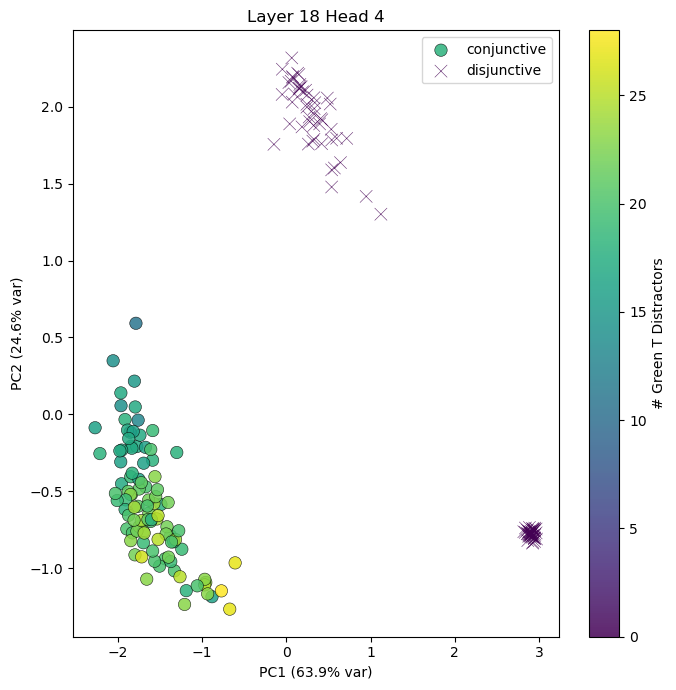

Saved ./pca_plots/L18_H4.png
L18H15: 200 vectors

=== L18 H15 ===
PC1: r=0.650, R²=0.422, slope=0.0672, p=2.587e-13
PC2: r=-0.675, R²=0.455, slope=-0.1594, p=1.396e-14


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

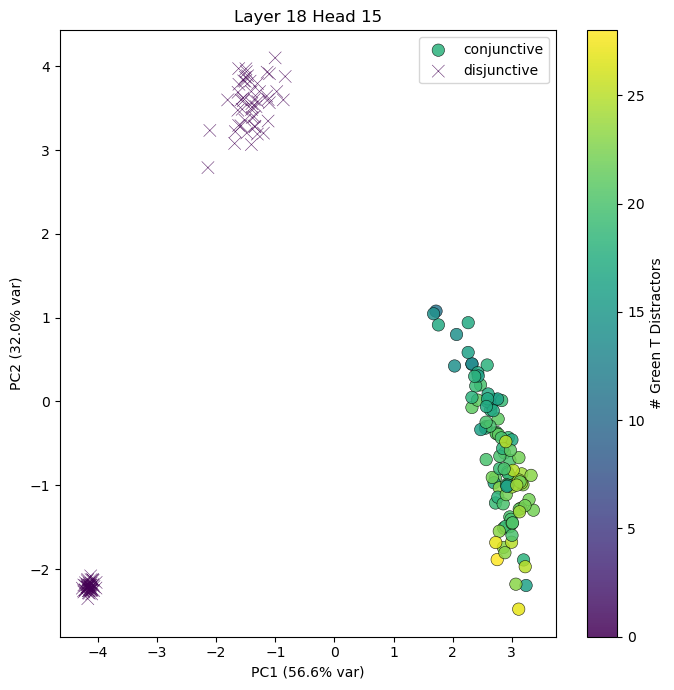

Saved ./pca_plots/L18_H15.png
L19H23: 200 vectors

=== L19 H23 ===
PC1: r=-0.513, R²=0.263, slope=-0.1447, p=4.844e-08
PC2: r=-0.462, R²=0.214, slope=-0.1587, p=1.275e-06


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

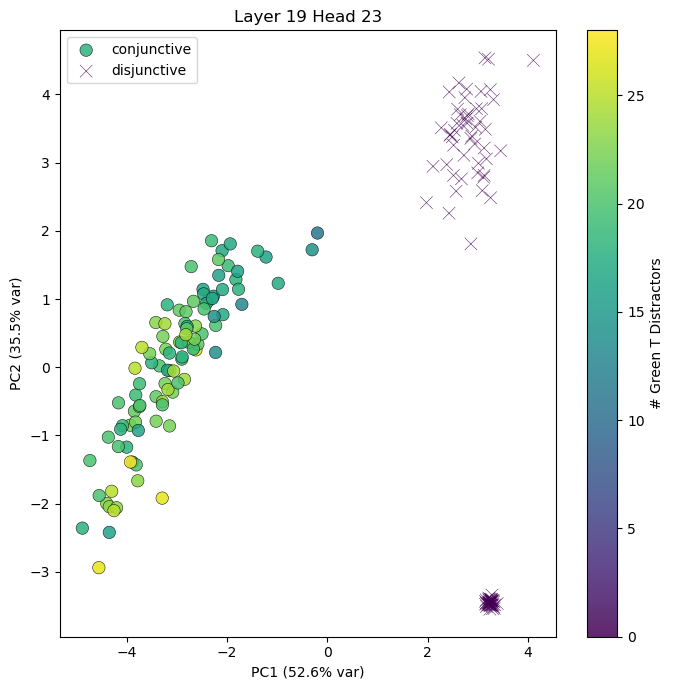

Saved ./pca_plots/L19_H23.png
L20H1: 200 vectors

=== L20 H1 ===
PC1: r=-0.519, R²=0.269, slope=-0.2143, p=3.143e-08
PC2: r=0.605, R²=0.367, slope=0.1688, p=2.520e-11


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

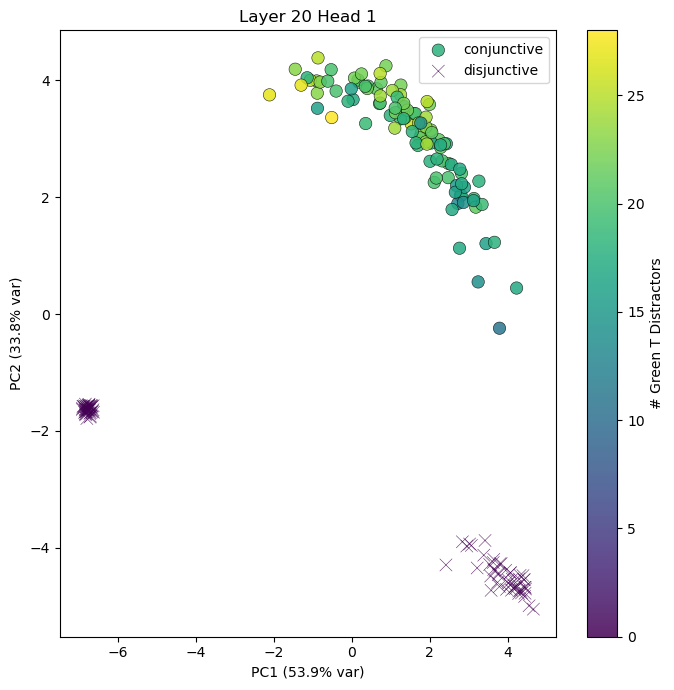

Saved ./pca_plots/L20_H1.png
L20H3: 200 vectors

=== L20 H3 ===
PC1: r=-0.487, R²=0.238, slope=-0.2729, p=2.699e-07
PC2: r=0.531, R²=0.282, slope=0.1940, p=1.290e-08


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

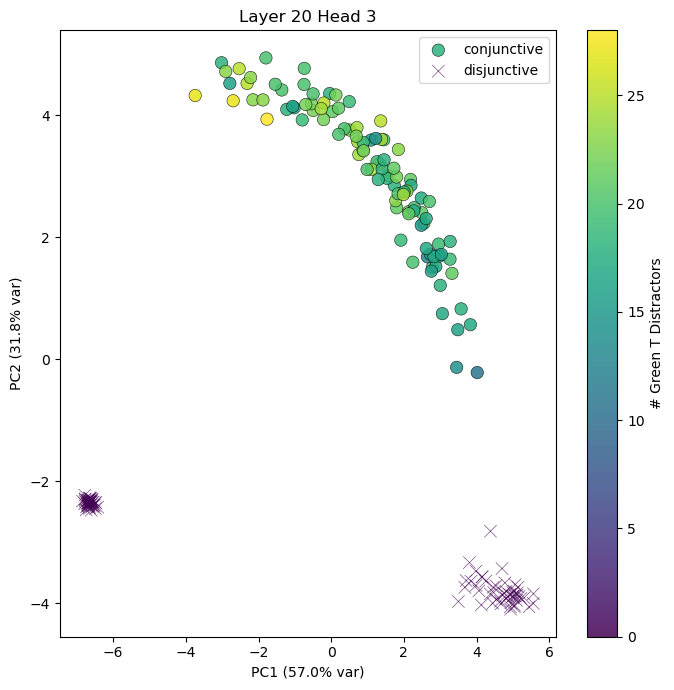

Saved ./pca_plots/L20_H3.png
L20H4: 200 vectors

=== L20 H4 ===
PC1: r=-0.547, R²=0.299, slope=-0.2171, p=4.033e-09
PC2: r=0.386, R²=0.149, slope=0.0491, p=7.200e-05


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

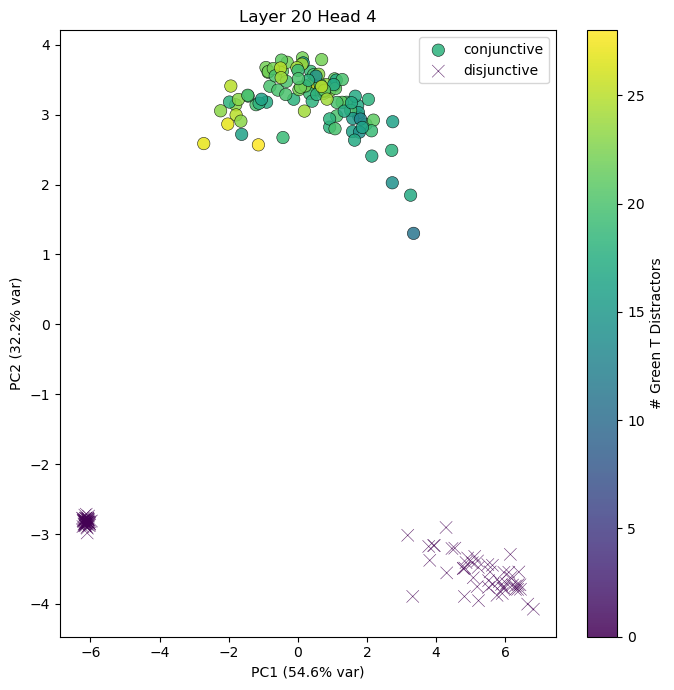

Saved ./pca_plots/L20_H4.png
L23H27: 200 vectors

=== L23 H27 ===
PC1: r=-0.502, R²=0.252, slope=-0.2012, p=1.001e-07
PC2: r=-0.553, R²=0.306, slope=-0.0642, p=2.397e-09


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

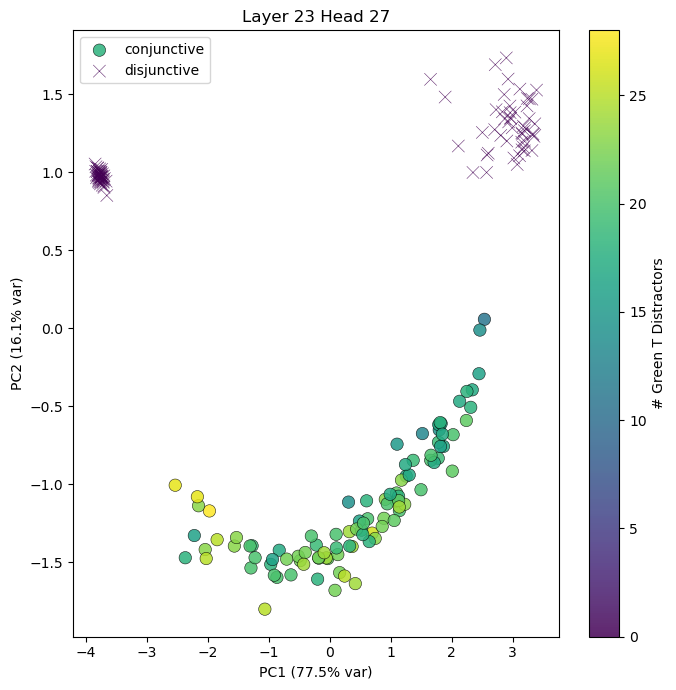

Saved ./pca_plots/L23_H27.png
L26H26: 200 vectors

=== L26 H26 ===
PC1: r=0.516, R²=0.266, slope=0.2080, p=3.854e-08
PC2: r=0.584, R²=0.342, slope=0.1263, p=1.719e-10


/tmp/ipykernel_1982302/1455933647.py:154: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(


<Figure size 640x480 with 0 Axes>

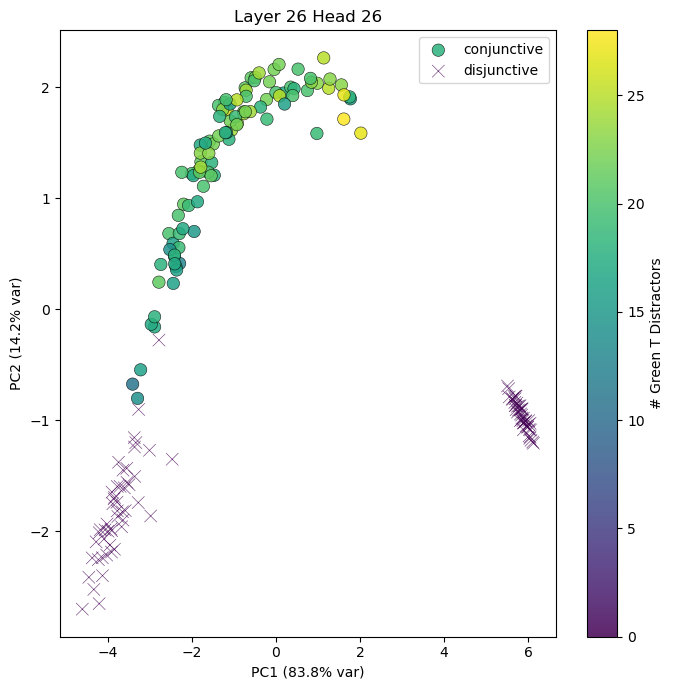

Saved ./pca_plots/L26_H26.png

Done.


<Figure size 640x480 with 0 Axes>

In [1]:


import os
import json

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA

print("Matplotlib backend:", matplotlib.get_backend())

# ==========================================================
# Paths
# ==========================================================

CSV_PATH = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/"
    "Results/top10_head_geometry.csv"
)

DATASET_ROOT = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/"
    "search-dataset/visual_search_dataset_counterfactual"
)

SAVE_DIR = "./pca_plots"
os.makedirs(SAVE_DIR, exist_ok=True)

# ==========================================================
# Load geometry
# ==========================================================

df = pd.read_csv(CSV_PATH)

df["layer"] = df["layer"].astype(int)
df["head"] = df["head"].astype(int)

feature_cols = sorted(
    [c for c in df.columns if c.startswith("dim_")]
)

print(f"{len(feature_cols)} dimensions")
print(f"{len(df)} vectors")

# ==========================================================
# Load metadata
# ==========================================================

metadata_cache = {}


def count_green_T(row):

    condition = row["condition"]
    distractors = int(row["num_distractors"])
    trial = int(row["trial"])
    target_present = str(row["target_present"]).lower()

    json_path = os.path.join(
        DATASET_ROOT,
        condition,
        f"{condition}_distractors_{distractors}"
        f"_trial_{trial:03d}"
        f"_target_{target_present}.json",
    )

    if json_path not in metadata_cache:
        with open(json_path, "r") as f:
            metadata_cache[json_path] = json.load(f)

    return sum(
        obj["shape"] == "T" and obj["color"] == "green"
        for obj in metadata_cache[json_path]["objects"]
    )


print("Loading metadata...")
df["green_T_distractors"] = df.apply(
    count_green_T,
    axis=1,
)

print(df["green_T_distractors"].value_counts().sort_index())

# ==========================================================
# PCA
# ==========================================================

heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
)

print()
print("Heads:")
print(heads)
print()

vmin = df["green_T_distractors"].min()
vmax = df["green_T_distractors"].max()

markers = {
    "conjunctive": "o",
    "disjunctive": "x",
}

for layer, head in heads.itertuples(index=False):

    sub = df[
        (df["layer"] == layer)
        & (df["head"] == head)
    ].copy()

    print(f"L{layer}H{head}: {len(sub)} vectors")

    if len(sub) < 2:
        print("Skipping")
        continue

    X = sub[feature_cols].values

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X)

    sub["PC1"] = coords[:, 0]
    sub["PC2"] = coords[:, 1]


    from scipy.stats import linregress

    print(f"\n=== L{layer} H{head} ===")
    conj = sub[sub["condition"] == "conjunctive"]
    for pc in ["PC1", "PC2"]:

        result = linregress(
            conj["green_T_distractors"],
            conj[pc],
        )

        print(
            f"{pc}: "
            f"r={result.rvalue:.3f}, "
            f"R²={result.rvalue**2:.3f}, "
            f"slope={result.slope:.4f}, "
            f"p={result.pvalue:.3e}"
        )

    fig, ax = plt.subplots(figsize=(7, 7))

    for condition in ["conjunctive", "disjunctive"]:

        pts = sub[sub["condition"] == condition]

        sc = ax.scatter(
            pts["PC1"],
            pts["PC2"],
            c=pts["green_T_distractors"],
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            marker=markers[condition],
            s=80,
            alpha=0.85,
            edgecolors="black",
            linewidths=0.4,
            label=condition,
        )

    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label("# Green T Distractors")

    ax.set_xlabel(
        f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% var)"
    )

    ax.set_ylabel(
        f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% var)"
    )

    ax.set_title(f"Layer {layer} Head {head}")

    ax.legend()

    plt.tight_layout()

    # Display
    plt.show(block=False)
    plt.pause(0.1)

    # Save as backup
    outfile = os.path.join(
        SAVE_DIR,
        f"L{layer}_H{head}.png",
    )
    plt.savefig(outfile, dpi=300)

    print(f"Saved {outfile}")

    plt.close(fig)

print("\nDone.")

128 dimensions
1600 total vectors
L18H4: 200 vectors


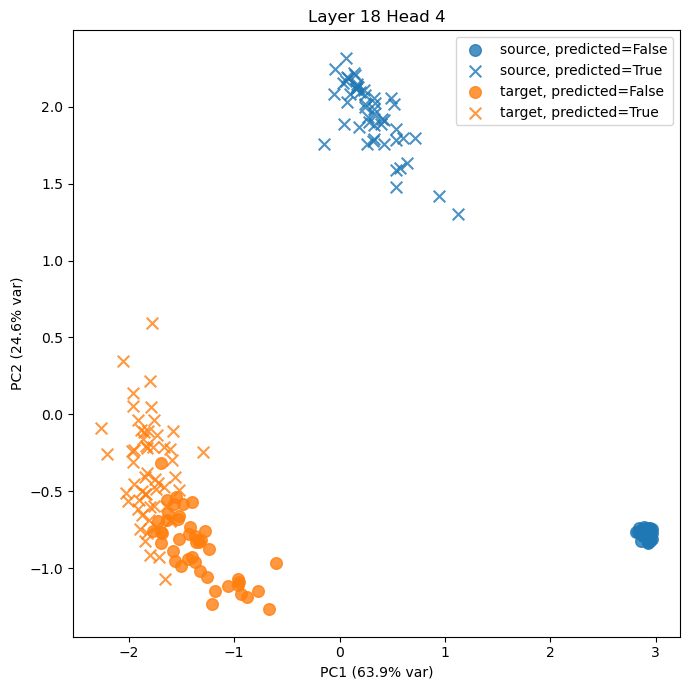

L18H15: 200 vectors


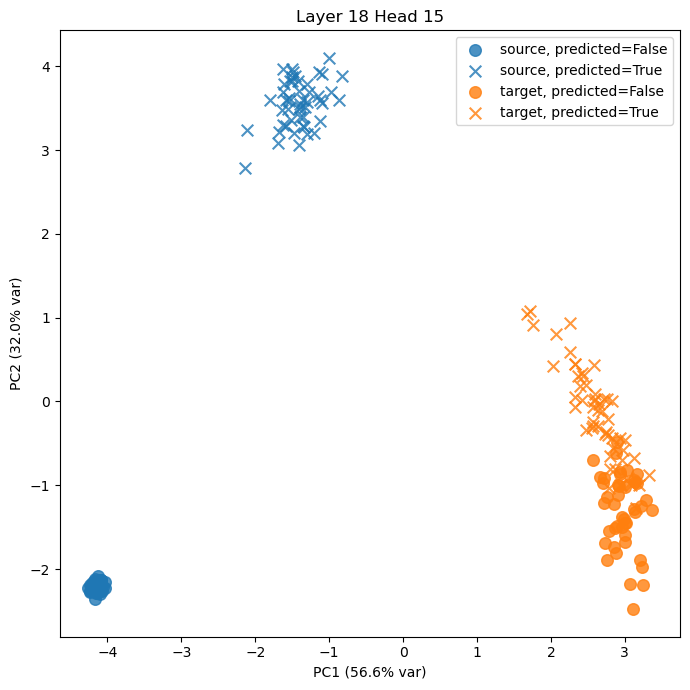

L19H23: 200 vectors


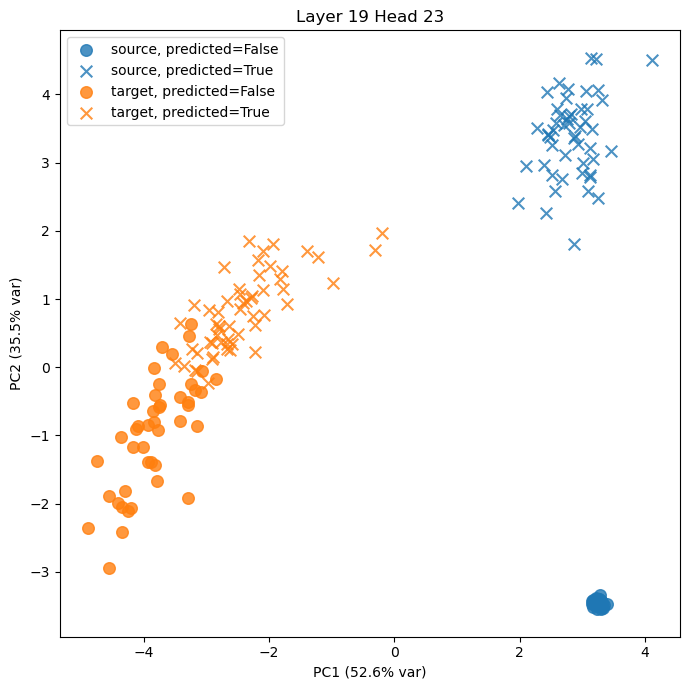

L20H1: 200 vectors


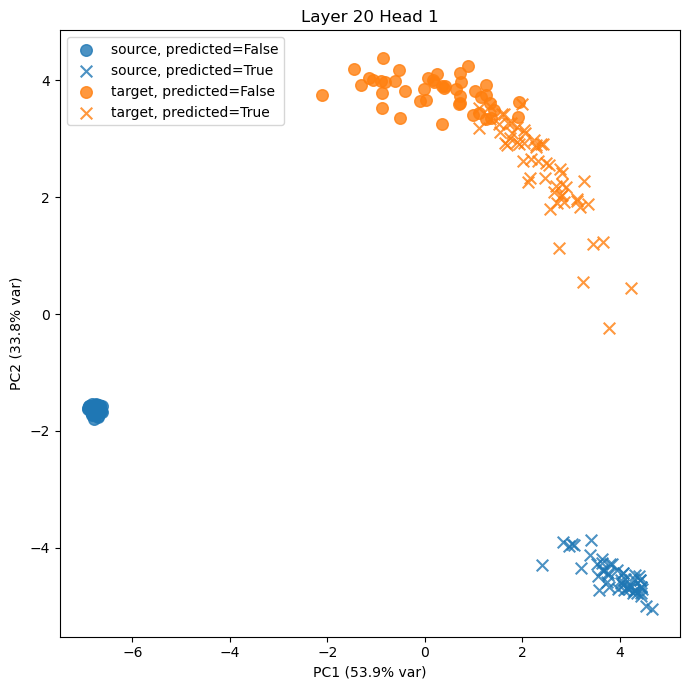

L20H3: 200 vectors


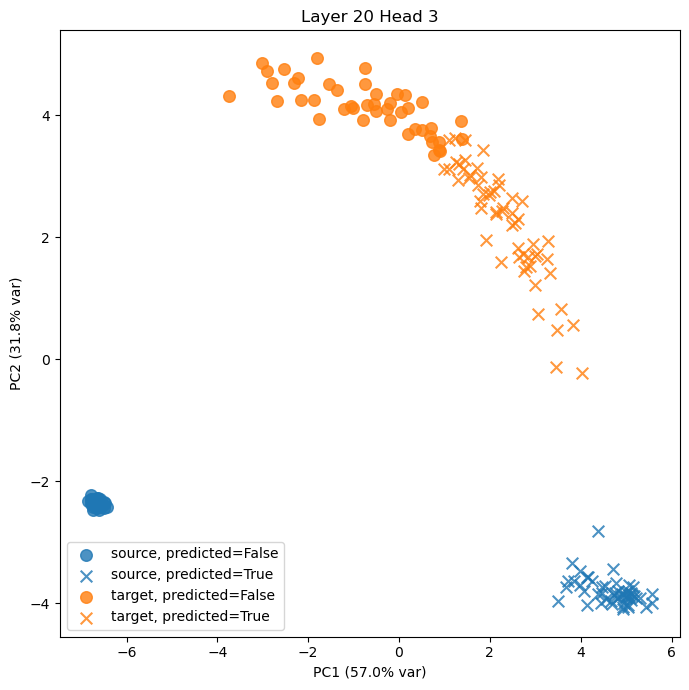

L20H4: 200 vectors


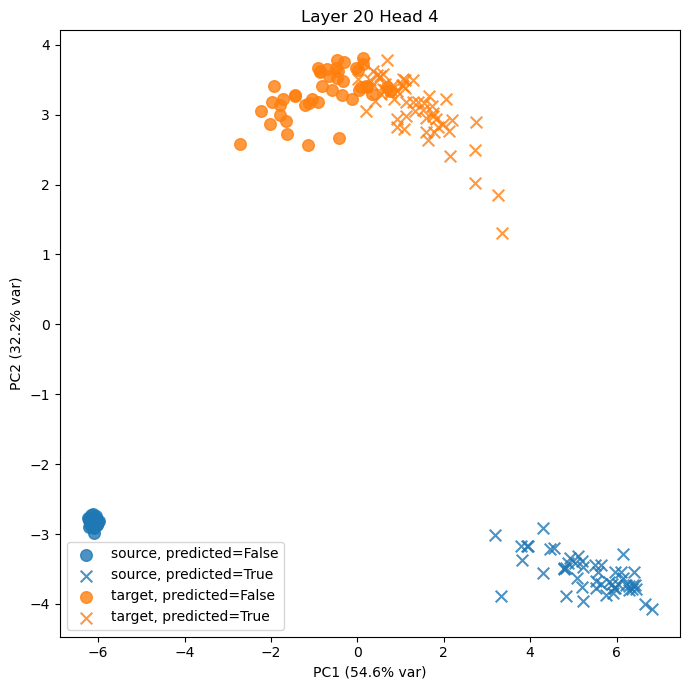

L23H27: 200 vectors


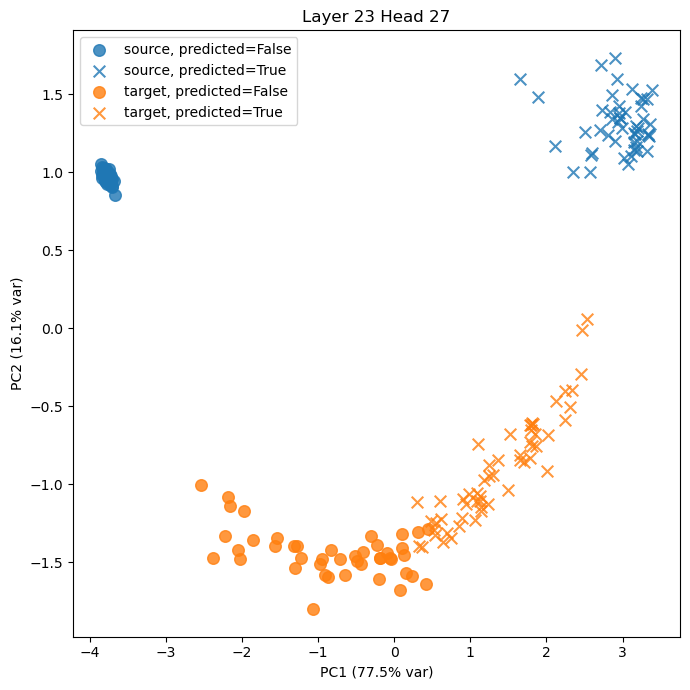

L26H26: 200 vectors


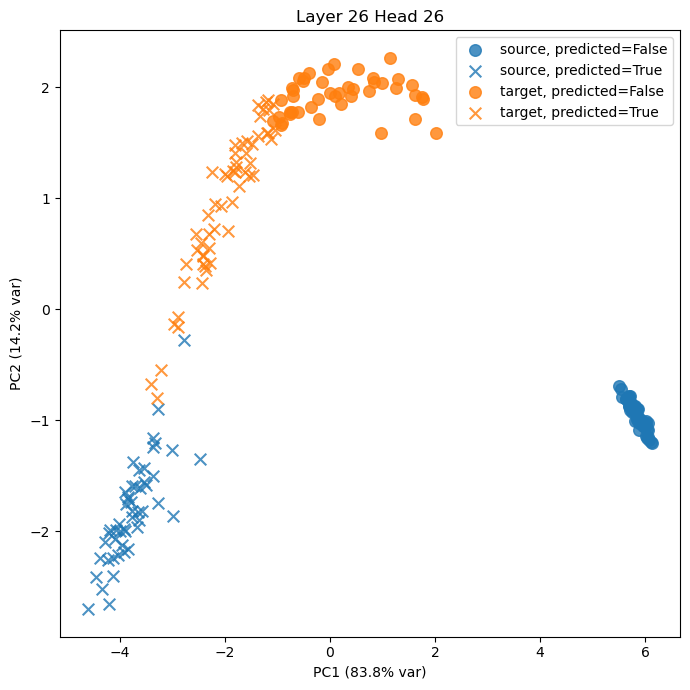

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================================
# Load data
# ==========================================================

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/top10_head_geometry.csv"
)

feature_cols = sorted(
    [c for c in df.columns if c.startswith("dim_")]
)

print(f"{len(feature_cols)} dimensions")
print(f"{len(df)} total vectors")

# ==========================================================
# PCA per head
# ==========================================================

heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
)

for layer, head in heads.itertuples(index=False):

    sub = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ].copy()

    print(f"L{layer}H{head}: {len(sub)} vectors")

    if len(sub) < 2:
        print("Skipping (not enough samples)")
        continue

    X = sub[feature_cols].to_numpy()

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X)

    sub["PC1"] = coords[:, 0]
    sub["PC2"] = coords[:, 1]

    plt.figure(figsize=(7, 7))

    # ------------------------------------------------------
    # Color = search condition
    # Marker = model prediction
    # ------------------------------------------------------

    colors = {
        "source": "tab:blue",     # disjunctive
        "target": "tab:orange",   # conjunctive
    }

    markers = {
        False: "o",   # predicted False
        True: "x",    # predicted True
    }

    for role in ["source", "target"]:
        for prediction in [False, True]:

            pts = sub[
                (sub["condition_role"] == role) &
                (sub["prediction"] == prediction)
            ]

            if len(pts) == 0:
                continue

            plt.scatter(
                pts["PC1"],
                pts["PC2"],
                color=colors[role],
                marker=markers[prediction],
                s=70,
                alpha=0.8,
                label=f"{role}, predicted={'True' if prediction else 'False'}",
            )

    plt.xlabel(
        f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% var)"
    )

    plt.ylabel(
        f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% var)"
    )

    plt.title(f"Layer {layer} Head {head}")

    plt.legend()

    plt.tight_layout()
    plt.show()

128 dimensions
1600 total vectors
L18H4: 200 vectors


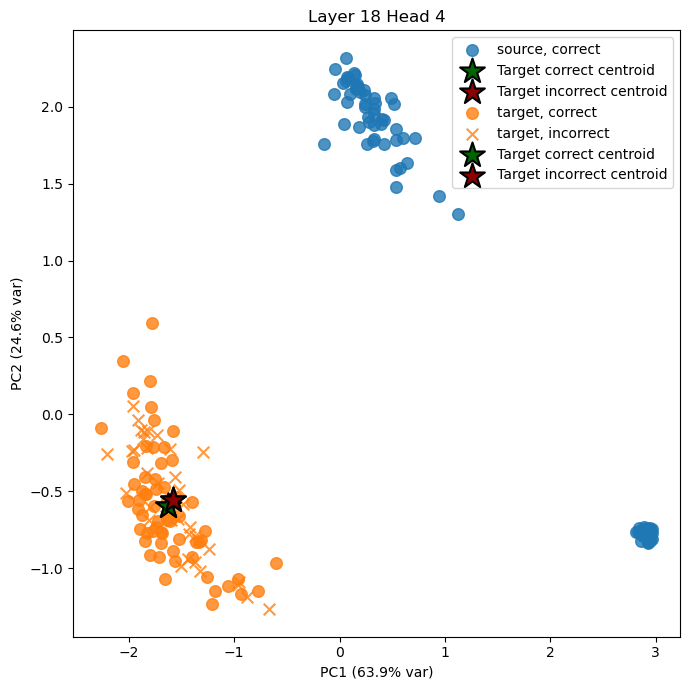

L18H15: 200 vectors


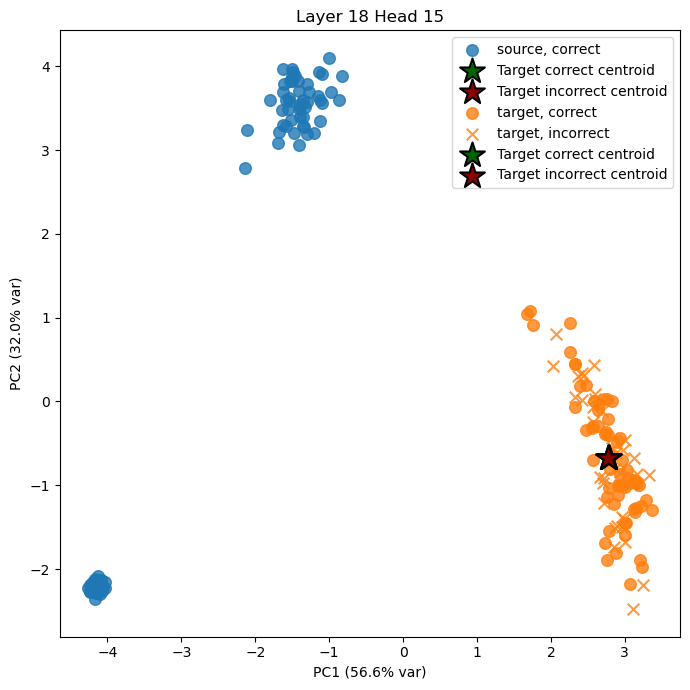

L19H23: 200 vectors


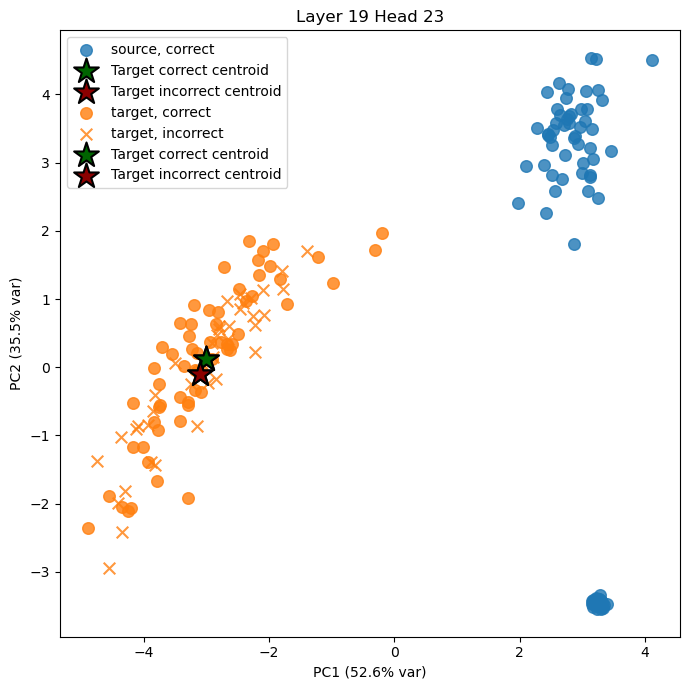

L20H1: 200 vectors


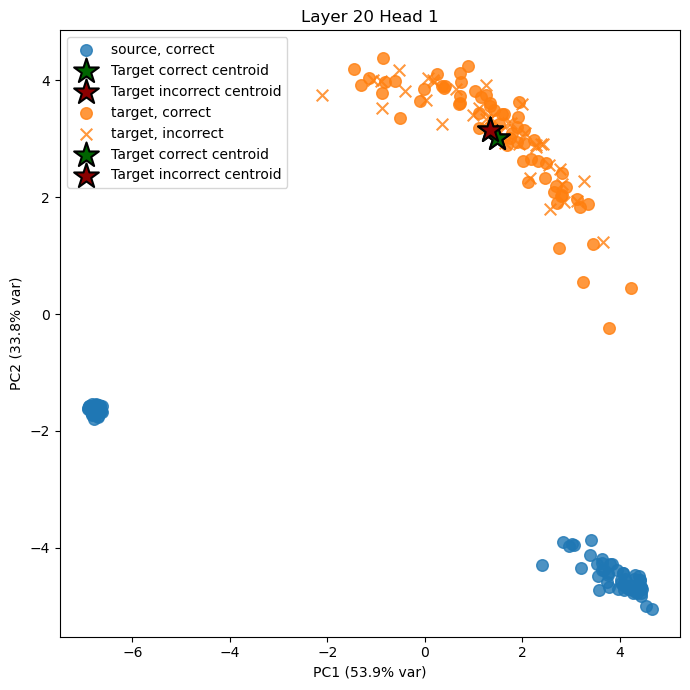

L20H3: 200 vectors


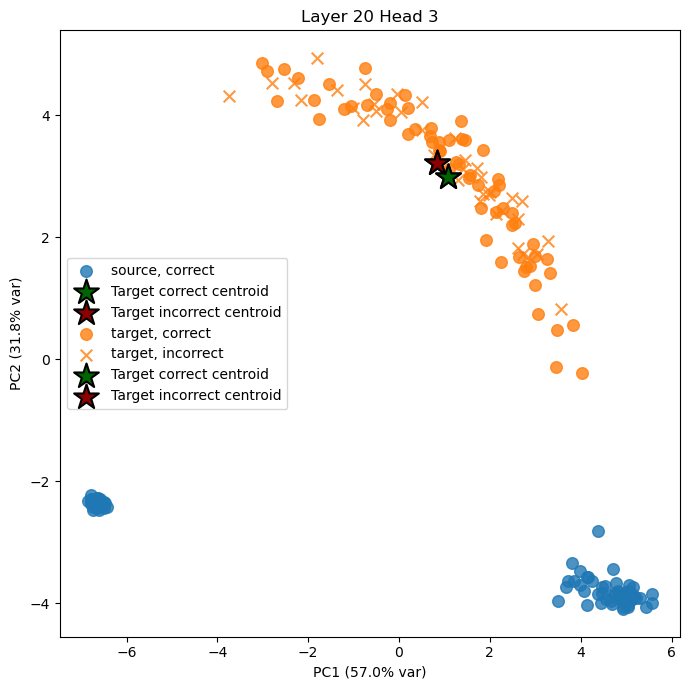

L20H4: 200 vectors


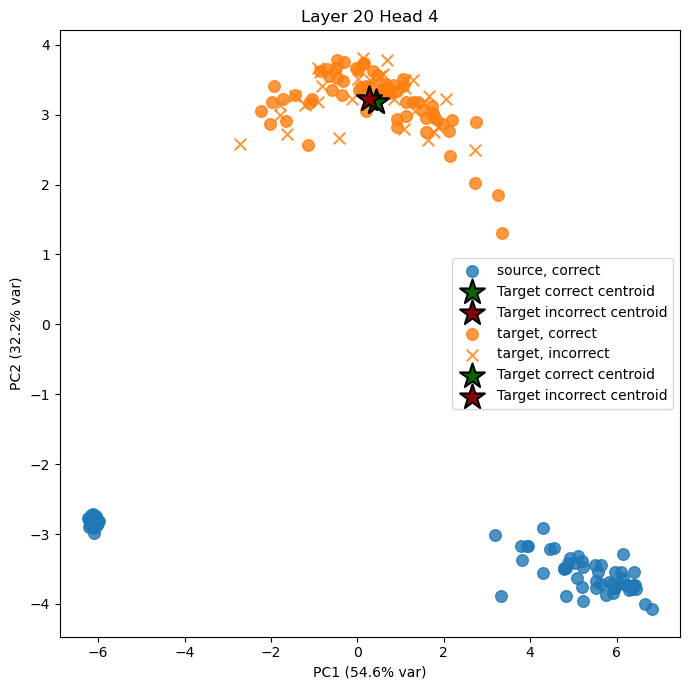

L23H27: 200 vectors


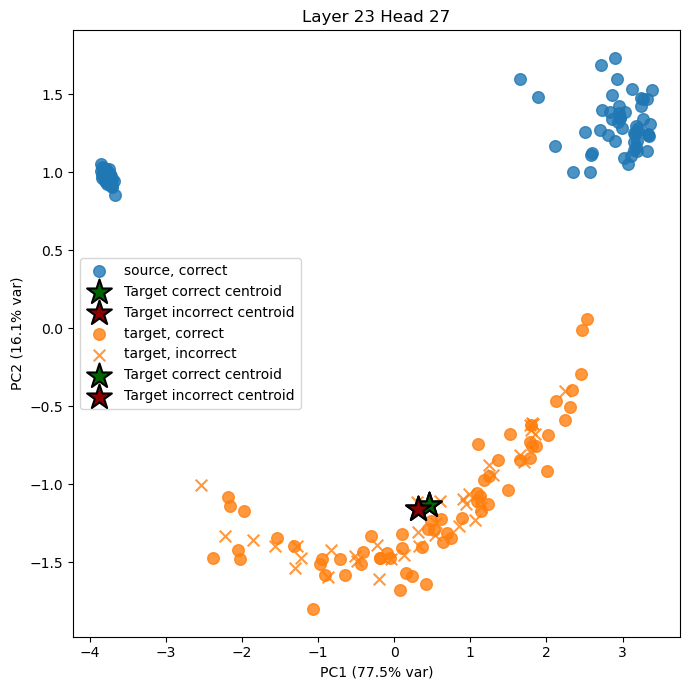

L26H26: 200 vectors


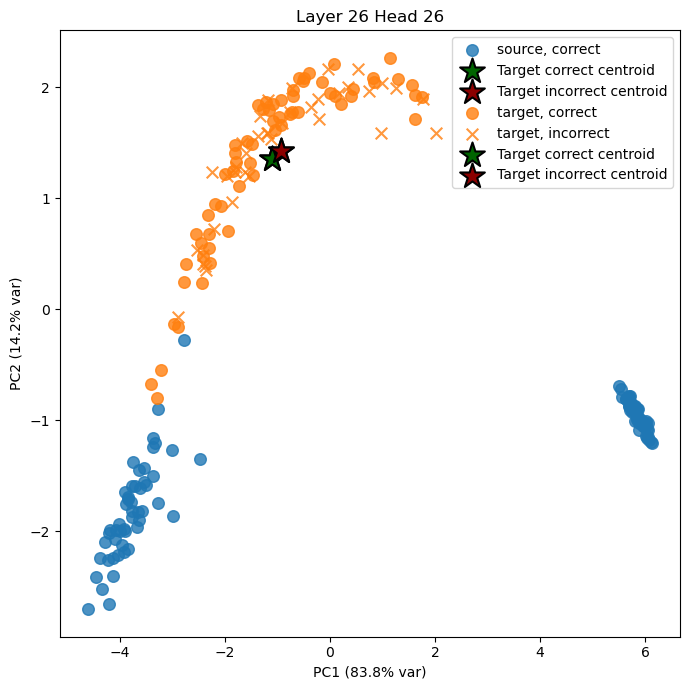

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================================
# Load data
# ==========================================================

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/top10_head_geometry.csv"
)

feature_cols = sorted(
    [c for c in df.columns if c.startswith("dim_")]
)

print(f"{len(feature_cols)} dimensions")
print(f"{len(df)} total vectors")

# ==========================================================
# PCA per head
# ==========================================================

heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
)

for layer, head in heads.itertuples(index=False):

    sub = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ].copy()

    print(f"L{layer}H{head}: {len(sub)} vectors")

    if len(sub) < 2:
        print("Skipping (not enough samples)")
        continue

    X = sub[feature_cols].to_numpy()

    pca = PCA(n_components=2)
    coords = pca.fit_transform(X)

    sub["PC1"] = coords[:, 0]
    sub["PC2"] = coords[:, 1]

    plt.figure(figsize=(7, 7))

    # ------------------------------------------------------
    # Color = search condition
    # Marker = correctness
    # ------------------------------------------------------

    colors = {
        "source": "tab:blue",
        "target": "tab:orange",
    }

    markers = {
        True: "o",   # correct
        False: "x",  # incorrect
    }

    for role in ["source", "target"]:
        for correct in [True, False]:

            pts = sub[
                (sub["condition_role"] == role) &
                (sub["correct"] == correct)
            ]

            if len(pts) == 0:
                continue

            plt.scatter(
                pts["PC1"],
                pts["PC2"],
                color=colors[role],
                marker=markers[correct],
                s=70,
                alpha=0.8,
                label=f"{role}, {'correct' if correct else 'incorrect'}",
            )


        # ------------------------------------------------------
        # Centroids for conjunctive (target) trials
        # ------------------------------------------------------

        centroid_colors = {
            True: "darkgreen",   # correct
            False: "darkred",    # incorrect
        }

        for correct in [True, False]:

            pts = sub[
                (sub["condition_role"] == "target") &
                (sub["correct"] == correct)
            ]

            if len(pts) == 0:
                continue

            centroid_x = pts["PC1"].mean()
            centroid_y = pts["PC2"].mean()

            plt.scatter(
                centroid_x,
                centroid_y,
                s=350,
                c=centroid_colors[correct],
                marker="*",
                edgecolors="black",
                linewidths=1.5,
                zorder=10,
                label=f"Target {'correct' if correct else 'incorrect'} centroid",
            )


    plt.xlabel(
        f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% var)"
    )

    plt.ylabel(
        f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% var)"
    )

    plt.title(f"Layer {layer} Head {head}")

    plt.legend()

    plt.tight_layout()
    plt.show()

In [23]:
print(df.shape)

print(df[["layer","head"]].head())

print(df["layer"].dtype)
print(df["head"].dtype)

print(df["layer"].unique()[:10])
print(df["head"].unique()[:10])

(1600, 153)
   layer  head
0     20     1
1     20     1
2     20     3
3     20     3
4     20     4
int64
int64
[20 26 23 19 18]
[ 1  3  4 26 27 23 15]


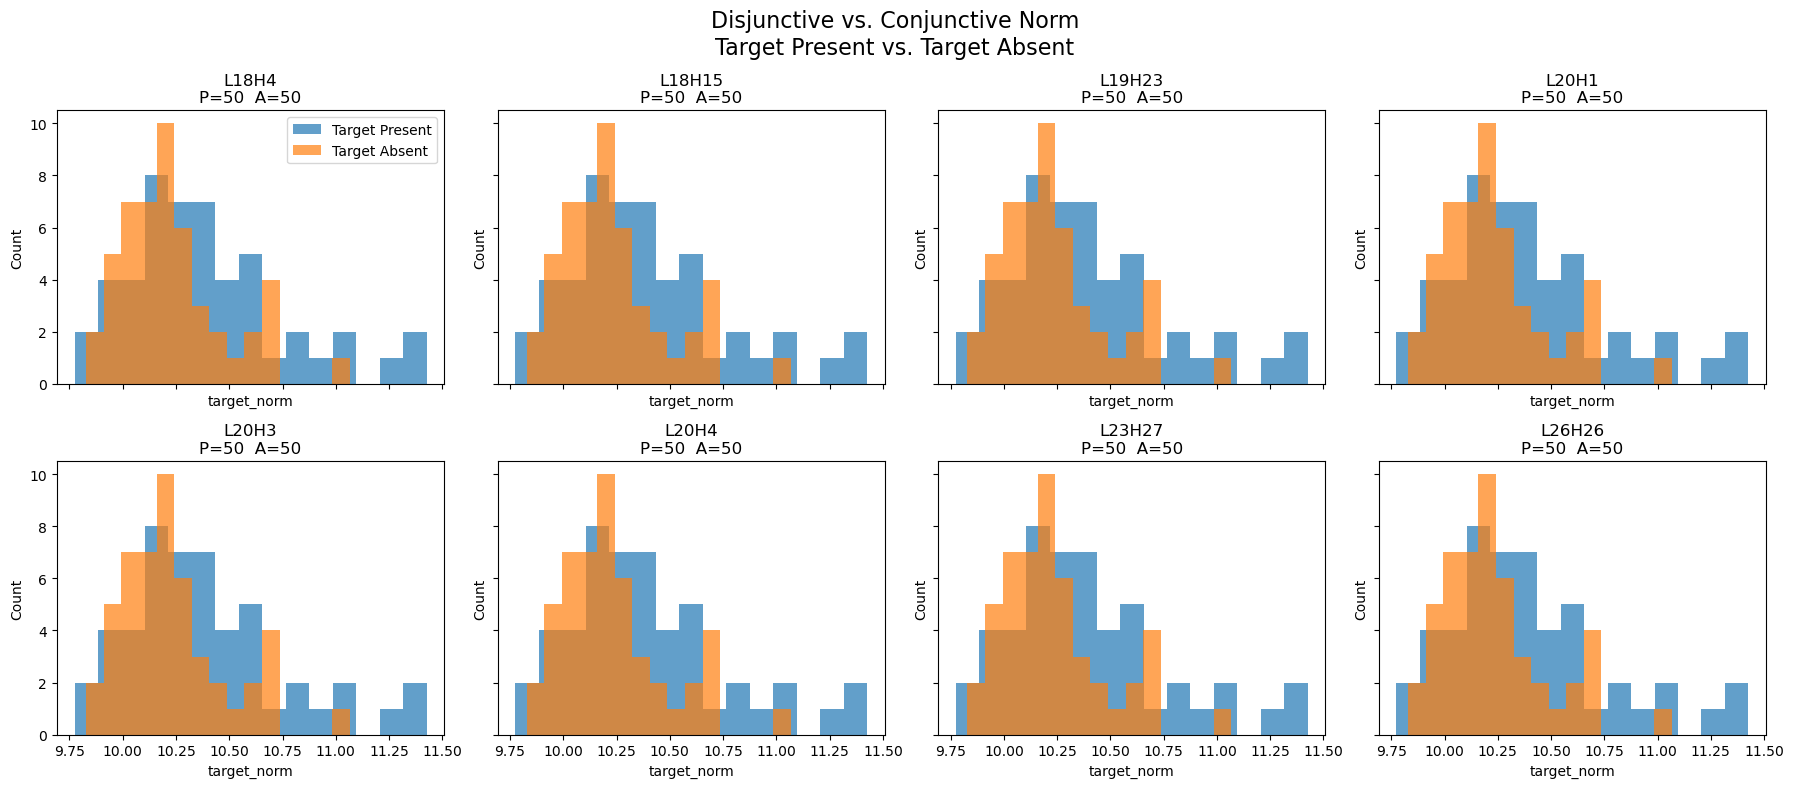

In [13]:

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/top10_head_geometry_pairs.csv"
)

heads = (
    df[["layer", "head"]]
    .drop_duplicates()
    .sort_values(["layer", "head"])
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (_, h) in zip(axes, heads.iterrows()):

    layer = h["layer"]
    head = h["head"]

    subset = df[
        (df["layer"] == layer) &
        (df["head"] == head)
    ]

    present["target_norm"]
    absent["target_norm"]

    ax.hist(
        present["target_norm"],
        bins=15,
        alpha=0.7,
        label="Target Present",
    )

    ax.hist(
        absent["target_norm"],
        bins=15,
        alpha=0.7,
        label="Target Absent",
    )

    ax.set_title(
        f"L{layer}H{head}\n"
        f"P={len(present)}  A={len(absent)}"
    )

    ax.set_xlabel("target_norm")
    ax.set_ylabel("Count")

axes[0].legend()

plt.suptitle(
    "Disjunctive vs. Conjunctive Norm\nTarget Present vs. Target Absent",
    fontsize=16,
)

plt.tight_layout()
plt.show()

# Scaling factor

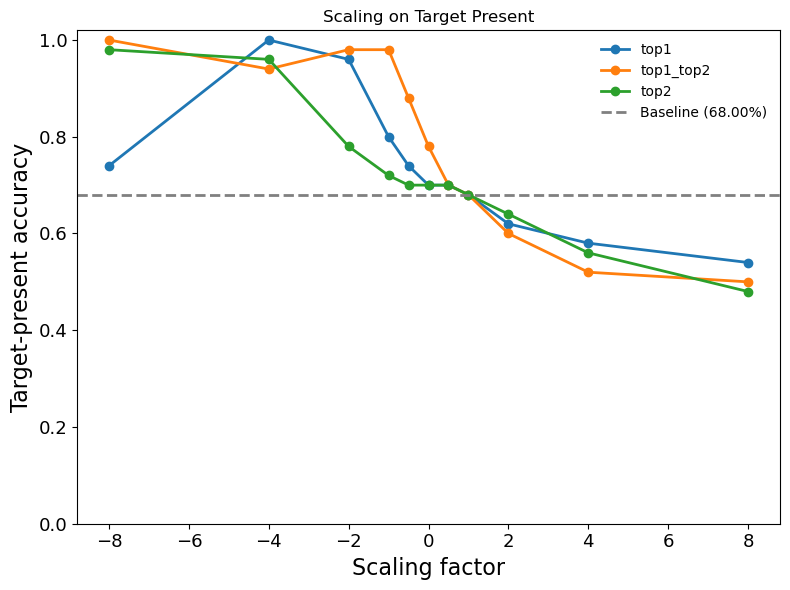

In [36]:


df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj40_top2_head_scaling_summary.csv"
)

plt.figure(figsize=(8,6))

for intervention in sorted(df["intervention"].unique()):

    sub = (
        df[df["intervention"] == intervention]
        .sort_values("scale")
    )

    plt.plot(
        sub["scale"],
        sub["scaled_present_accuracy"],
        marker="o",
        linewidth=2,
        label=intervention,
    )

baseline = df["baseline_present_accuracy"].iloc[0]

plt.axhline(
    baseline,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"Baseline ({baseline:.2%})",
)

plt.xlabel("Scaling factor", fontsize=16)
plt.ylabel("Target-present accuracy", fontsize=16)
plt.title("Scaling on Target Present")

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.ylim(0, 1.02)

plt.legend(frameon=False)
plt.tight_layout()
plt.show()

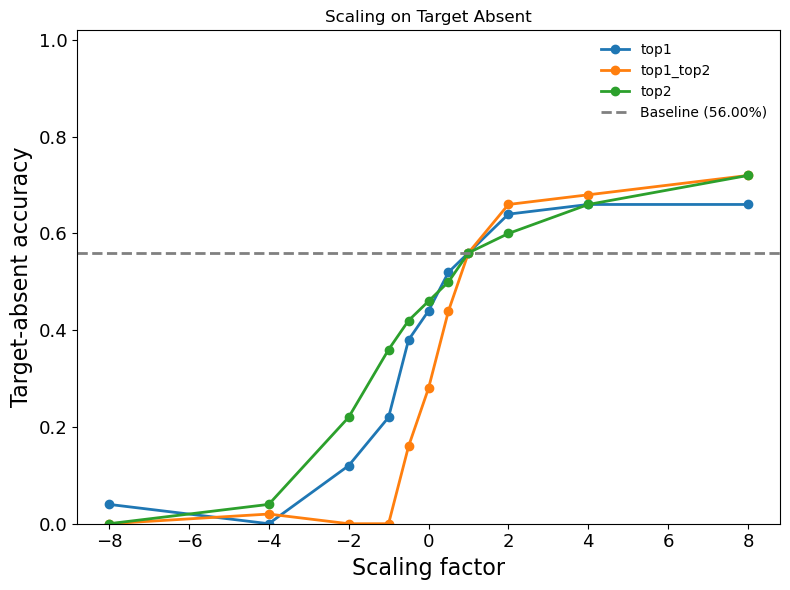

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj40_top2_head_scaling_summary.csv"
)

plt.figure(figsize=(8,6))

for intervention in sorted(df["intervention"].unique()):

    sub = (
        df[df["intervention"] == intervention]
        .sort_values("scale")
    )

    plt.plot(
        sub["scale"],
        sub["scaled_absent_accuracy"],
        marker="o",
        linewidth=2,
        label=intervention,
    )

baseline = df["baseline_absent_accuracy"].iloc[0]

plt.axhline(
    baseline,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"Baseline ({baseline:.2%})",
)

plt.xlabel("Scaling factor", fontsize=16)
plt.ylabel("Target-absent accuracy", fontsize=16)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.ylim(0, 1.02)
plt.title("Scaling on Target Absent")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [32]:
df.columns

Index(['intervention', 'intervention_heads', 'n_intervened_heads', 'scale',
       'position_mode', 'query_position', 'n', 'n_target_present',
       'n_target_absent', 'baseline_accuracy', 'scaled_accuracy',
       'accuracy_change', 'baseline_present_accuracy',
       'scaled_present_accuracy', 'present_accuracy_change',
       'baseline_absent_accuracy', 'scaled_absent_accuracy',
       'absent_accuracy_change', 'baseline_true_rate', 'scaled_true_rate',
       'true_rate_change', 'mean_baseline_margin', 'mean_scaled_margin',
       'mean_delta_margin', 'std_delta_margin', 'median_delta_margin',
       'mean_abs_delta_margin', 'prediction_flip_rate',
       'correctness_change_rate'],
      dtype='object')

In [15]:
import pandas as pd

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj40_top2_head_scaling_summary.csv"
)

print(df.columns.tolist())

['intervention', 'intervention_heads', 'n_intervened_heads', 'scale', 'position_mode', 'query_position', 'n', 'n_target_present', 'n_target_absent', 'baseline_accuracy', 'scaled_accuracy', 'accuracy_change', 'baseline_present_accuracy', 'scaled_present_accuracy', 'present_accuracy_change', 'baseline_absent_accuracy', 'scaled_absent_accuracy', 'absent_accuracy_change', 'baseline_true_rate', 'scaled_true_rate', 'true_rate_change', 'mean_baseline_margin', 'mean_scaled_margin', 'mean_delta_margin', 'std_delta_margin', 'median_delta_margin', 'mean_abs_delta_margin', 'prediction_flip_rate', 'correctness_change_rate']
